# Phase 1 – Part A: Problem Understanding & Data Exploration
## Executive Clinical Screening & Triage Decision-Support Tool
**SWE485 – King Saud University – Group 3**

## 1. Introduction & Problem Statement

### 1.1 Domain
This project belongs to the **healthcare operations** domain. It focuses on early screening and triage for diabetes risk.

### 1.2 Problem Statement
Diabetes is one of the most common chronic diseases, and a large share of people with prediabetes or diabetes are unaware of their condition until complications appear. Healthcare organizations have limited clinical capacity, so they need an efficient way to decide **who should be prioritized for further clinical assessment**.

This project develops an **executive clinical screening and triage decision-support system** that classifies individuals into one of two screening categories based on health and lifestyle indicators:

- **0 – No Diabetes:** routine follow-up.
- **1 – Prediabetes or Diabetes:** recommended for further clinical assessment.

The system uses indicators such as BMI, high blood pressure, high cholesterol, physical activity, smoking, age group, and self-rated general health.

### 1.3 Type of Advice System
The system is a **medical screening and prioritization advice system** aimed at healthcare decision-makers. Its output is a recommendation on whether an individual should be referred for clinical assessment, together with (in Phase 2) a risk segment and an AI-generated preventive care summary.

### 1.4 Intended Users
- **Healthcare executives and managers:** to plan screening programs and allocate resources.
- **Healthcare professionals:** to prioritize individuals for clinical follow-up.

### 1.5 Scope and Limitations
- The system is a **screening and decision-support tool, not a medical diagnosis tool**. Final decisions remain with qualified clinicians.
- Because the goal is early screening, **missing an at-risk individual (false negative) is more costly than an extra referral (false positive)**. Recall on the positive class will therefore be a key evaluation priority in Part B.

## 2. Dataset Selection & Justification

### 2.1 Dataset Source
- **Name:** Diabetes Health Indicators Dataset
- **Source:** Kaggle – https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
- **File used:** `diabetes_binary_5050split_health_indicators_BRFSS2015.csv`
- **Origin:** Derived from the CDC's **Behavioral Risk Factor Surveillance System (BRFSS) 2015**, an annual health-related telephone survey in the United States.

### 2.2 Dataset Goal
The dataset was prepared to study which health and lifestyle indicators are associated with diabetes, and to support building predictive models for diabetes risk. This matches our goal of classifying screening status.

### 2.3 Dataset Overview
| Property | Value |
|---|---|
| Records | 70,692 |
| Predictor features | 21 |
| Target variable | `Diabetes_binary` |
| Classes | 0 = No Diabetes, 1 = Prediabetes or Diabetes |
| Class balance | 50 / 50 |
| Data type | Structured / tabular |

### 2.4 Justification

**Relevance**
- The features (BMI, HighBP, HighChol, PhysActivity, Smoker, Age, GenHlth, and others) are well-known diabetes risk factors and are exactly the inputs a screening tool would rely on.
- The binary target directly represents our screening decision: refer for assessment or not.

**Completeness**
- Each record contains all 21 indicators, covering health conditions, lifestyle behaviors, healthcare access, and demographics.
- The dataset has no significant missing values, which reduces the need for imputation.

**Quality**
- It comes from a large, standardized public health survey (CDC BRFSS), not an ad-hoc collection.
- The balanced 50/50 version avoids the strong class imbalance of the original data, so models are not biased toward the majority class.

**Fit with project requirements**
- Size: 70,692 rows, well above the minimum of several hundred.
- Features: 21, above the 10–15 minimum.
- Structure: tabular, as required for Phase 1.
- Classes: 2, suitable for binary classification.
- Phase 2: after removing the target, the features can be used for clustering to create patient risk segments.

### 2.5 Known Limitations
- **Self-reported data:** survey answers may contain recall or reporting bias.
- **Coarse features:** blood pressure and cholesterol are binary (yes/no), and age is given in 13 groups rather than exact years.
- **Combined positive class:** prediabetes and diabetes are merged into one class.
- **Artificial balance:** the 50/50 split does not reflect real-world prevalence, so predicted probabilities should be interpreted with care.
- **Population:** the data represents U.S. adults in 2015 and may not generalize directly to other populations.

## 3. Initial Data Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [2]:
import os

# Folder where the EDA figures are saved (next to this notebook)
os.makedirs("EDA_plots", exist_ok=True)

print("Shape (rows, columns):", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print()
df.info()

Shape (rows, columns): (70692, 22)

Duplicate rows: 1635

Total missing values: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  

**Observations:**
- The dataset contains 70,692 records and 22 columns (21 predictors + the target `Diabetes_binary`).
- There are no missing values.
- There are 1,635 duplicate rows (about 2.3% of the data). In survey data, two respondents can legitimately give identical answers, so duplicates are not necessarily errors. The decision to keep or remove them is left to the Preprocessing stage.
- All columns are stored as `float64`, even though most of them are binary (0/1) or ordinal categories (e.g., `Age`, `GenHlth`, `Education`, `Income`). Only `BMI`, `MentHlth`, and `PhysHlth` are truly numeric.

## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution

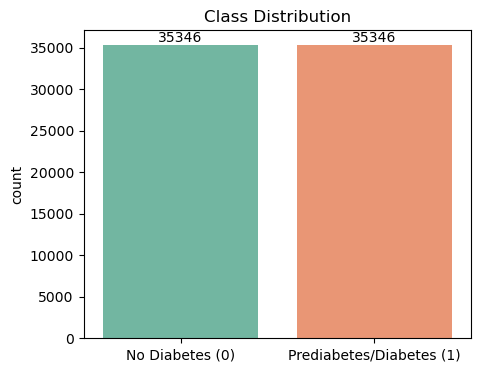

In [3]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Diabetes_binary", hue="Diabetes_binary", data=df,
                   palette="Set2", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No Diabetes (0)", "Prediabetes/Diabetes (1)"])
ax.set_title("Class Distribution")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.savefig("EDA_plots/01_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** The number of records in each class of the target variable.

**Observation:** The classes in our dataset are perfectly balanced, with 35,346 records in each class.

**Why it matters:** If one class were much larger than the other, a model could become "lazy" and simply predict the majority class every time. It would look accurate, but it would not really learn anything and would not be useful for us. Since our classes are balanced, we avoid this problem.

**Limitation:** This balance comes from a pre-processed version of the original BRFSS data (the full dataset is heavily imbalanced). Real-world prevalence of diabetes is much lower than 50%, so model performance on this version may not reflect performance on a real population.

### 4.2 BMI Distribution

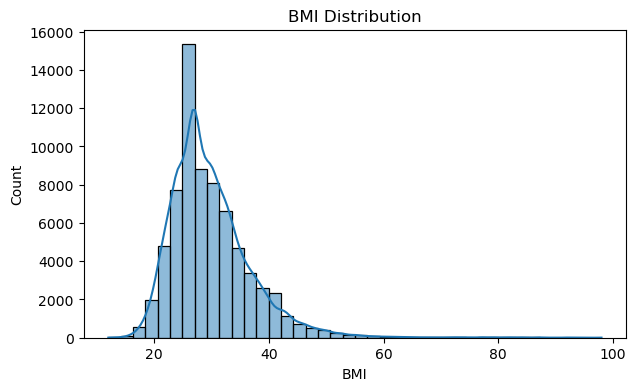

count    70692.000000
mean        29.856985
std          7.113954
min         12.000000
25%         25.000000
50%         29.000000
75%         33.000000
max         98.000000
Name: BMI, dtype: float64

In [4]:
plt.figure(figsize=(7, 4))
sns.histplot(df["BMI"], bins=40, kde=True)
plt.title("BMI Distribution")
plt.savefig("EDA_plots/02_bmi_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

df["BMI"].describe()

**What it shows:** The distribution of Body Mass Index (BMI) across all respondents.

**Observation:** Most respondents have a BMI around 26-27, where the histogram peaks (about 15,000 records). After the peak, the counts drop noticeably and a long, thin tail stretches to the right toward very high values. The values close to 98 are very unlikely to be realistic and are most likely recording errors.

**Why it matters:** These extreme values can affect scaling and some models, so Preprocessing should decide whether to cap or remove them.

### 4.3 BMI by Diabetes Status

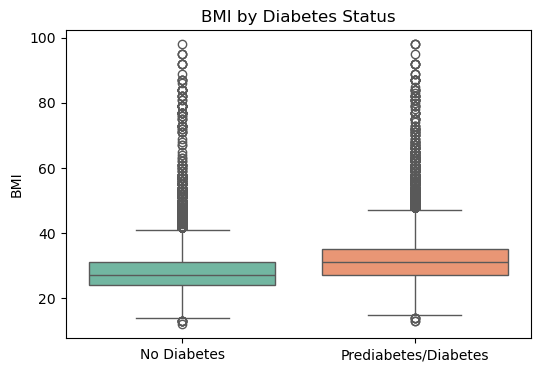

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0.0,35346.0,27.769960,6.187636,12.0,24.0,27.0,31.0,98.0
1.0,35346.0,31.944011,7.363401,13.0,27.0,31.0,35.0,98.0


In [5]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="Diabetes_binary", y="BMI", hue="Diabetes_binary", data=df,
            palette="Set2", legend=False)
plt.xticks([0, 1], ["No Diabetes", "Prediabetes/Diabetes"])
plt.xlabel("")
plt.title("BMI by Diabetes Status")
plt.savefig("EDA_plots/03_bmi_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("Diabetes_binary")["BMI"].describe()

**What it shows:** The distribution of BMI for each class, using box plots.

**Observation:** The box for the diabetes group sits higher than the box for the no-diabetes group (median about 31 vs. 27). However, the two boxes overlap, so BMI alone does not clearly separate the groups. Both groups also have many high outliers (the circles above the whiskers), reaching up to 98.

**Why it matters:** BMI is useful but not enough on its own, so our models will need to combine it with other features.

### 4.4 Diabetes Rate by Age Category

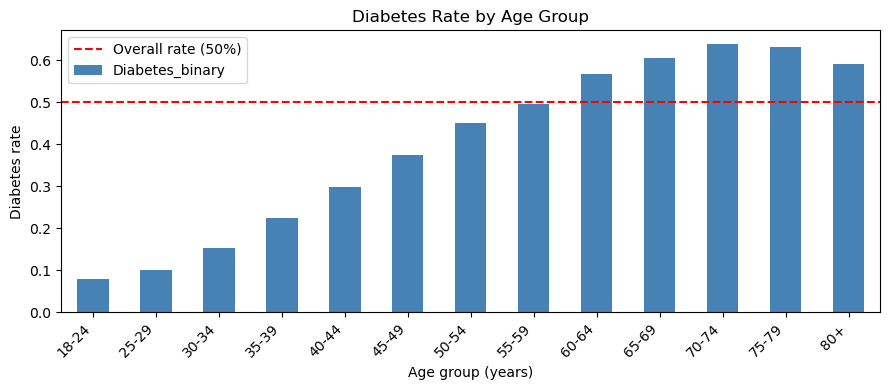

Age
1.0     0.079673
2.0     0.100287
3.0     0.153245
4.0     0.224132
5.0     0.298580
6.0     0.374785
7.0     0.449360
8.0     0.495525
9.0     0.566950
10.0    0.604090
11.0    0.639110
12.0    0.630886
13.0    0.591412
Name: Diabetes_binary, dtype: float64

In [6]:
age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

plt.figure(figsize=(9, 4))
age_rate = df.groupby("Age")["Diabetes_binary"].mean()
ax = age_rate.plot(kind="bar", color="steelblue")
ax.set_xticklabels(age_labels, rotation=45, ha="right")
plt.ylabel("Diabetes rate")
plt.xlabel("Age group (years)")
plt.title("Diabetes Rate by Age Group")
plt.axhline(0.5, color="red", linestyle="--", label="Overall rate (50%)")
plt.legend()
plt.tight_layout()
plt.savefig("EDA_plots/04_age_vs_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

age_rate

**What it shows:** The share of respondents with prediabetes/diabetes within each age group. The red dashed line marks the overall rate of 50%.

**Observation:** The diabetes rate increases with age, from about 8% in the youngest group to about 64% at ages 70-74. In the last two groups (75-79 and 80+), the rate starts to decrease slightly.

**Why it matters:** Age is a strong signal for risk prioritization. The slight drop in the oldest groups cannot be explained from our data. Possible reasons include survivorship effects or smaller sample sizes, but we do not draw conclusions about the cause. Also, the exact percentages reflect our balanced sample, not real population rates.

### 4.5 Diabetes Rate by Binary Risk Factors

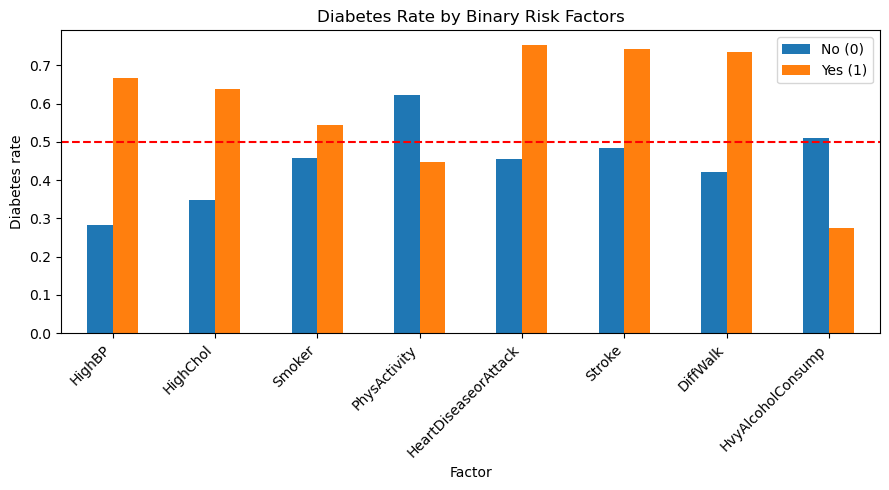

,No (0),Yes (1)
Factor,,
HighBP,0.283,0.668
HighChol,0.348,0.637
Smoker,0.459,0.545
PhysActivity,0.622,0.448
HeartDiseaseorAttack,0.456,0.754
Stroke,0.484,0.744
DiffWalk,0.421,0.734
HvyAlcoholConsump,0.510,0.275


In [7]:
risk = ["HighBP", "HighChol", "Smoker", "PhysActivity",
        "HeartDiseaseorAttack", "Stroke", "DiffWalk", "HvyAlcoholConsump"]

rows = []
for c in risk:
    g = df.groupby(c)["Diabetes_binary"].mean()
    rows.append({"Factor": c, "No (0)": g[0.0], "Yes (1)": g[1.0]})
rate_df = pd.DataFrame(rows).set_index("Factor")

rate_df.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Diabetes rate")
plt.title("Diabetes Rate by Binary Risk Factors")
plt.axhline(0.5, color="red", linestyle="--")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("EDA_plots/05_risk_factors.png", dpi=150, bbox_inches="tight")
plt.show()

rate_df.round(3)

**What it shows:** The diabetes rate for respondents without (No) and with (Yes) each binary factor.

**Observation:** HighBP shows the biggest difference: the diabetes rate is about 28% without high blood pressure and 67% with it. It is followed by DiffWalk, heart disease, and high cholesterol. Physical activity shows the expected direction: active people have a lower diabetes rate (45% vs. 62%). Smoking shows the weakest difference. Heavy alcohol consumption shows an unexpected direction, but this group is small (about 4% of the data), so we do not interpret it.

**Why it matters:** These factors can help prioritize who should be screened first. The plot shows association, not causation.

### 4.6 Diabetes Rate by General Health

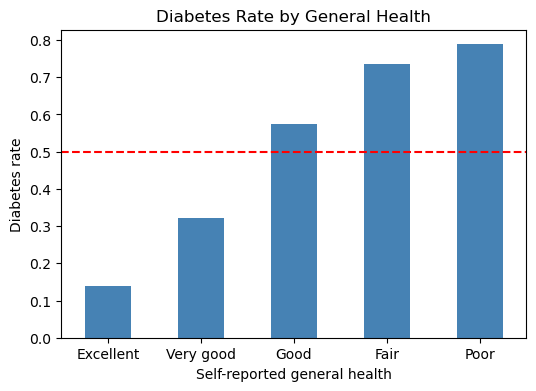

GenHlth
Excellent    0.138
Very good    0.321
Good         0.574
Fair         0.736
Poor         0.788
Name: Diabetes_binary, dtype: float64

In [8]:
gh_labels = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}
gh_rate = df.groupby("GenHlth")["Diabetes_binary"].mean()
gh_rate.index = gh_rate.index.map(gh_labels)

plt.figure(figsize=(6, 4))
gh_rate.plot(kind="bar", color="steelblue")
plt.ylabel("Diabetes rate")
plt.xlabel("Self-reported general health")
plt.title("Diabetes Rate by General Health")
plt.axhline(0.5, color="red", linestyle="--")
plt.xticks(rotation=0)
plt.savefig("EDA_plots/06_genhlth_vs_diabetes.png", dpi=150, bbox_inches="tight")
plt.show()

gh_rate.round(3)

**What it shows:** The diabetes rate for each level of self-reported general health (1 = Excellent to 5 = Poor).

**Observation:** The diabetes rate increases as self-reported health gets worse, from about 14% among people who rate their health as excellent to about 79% among those who rate it as poor.

**Why it matters:** General health is a simple indicator that is strongly related to diabetes and could be useful in our screening system. Since it is self-reported, it may partly reflect people who already have diabetes or other conditions rating their health lower, so we do not treat it as a cause.

### 4.7 Correlation Heatmap

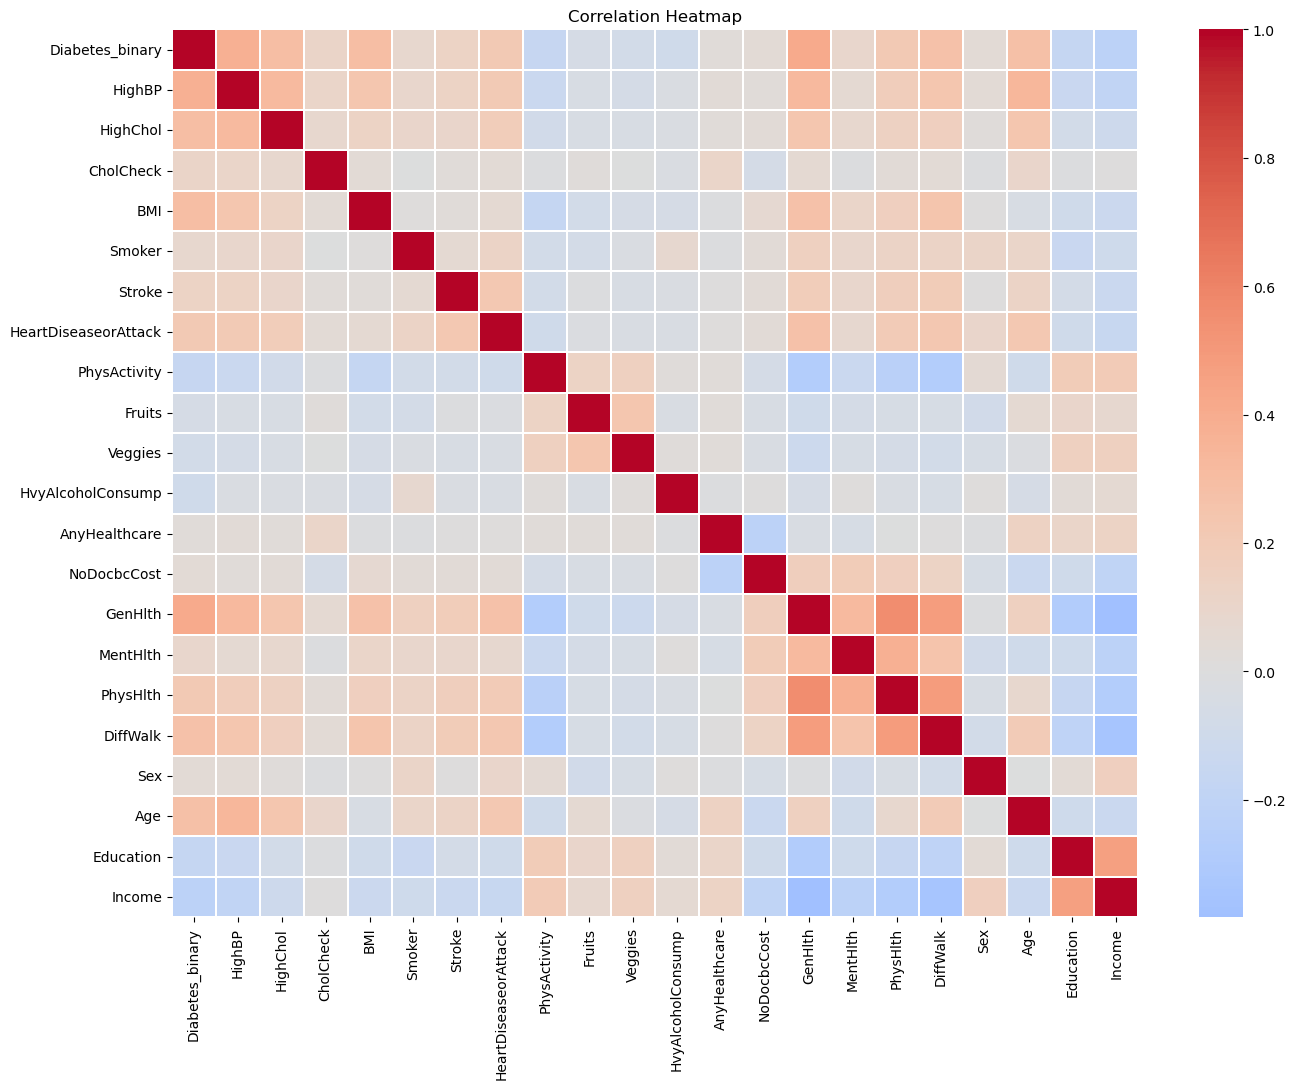

In [9]:
plt.figure(figsize=(14, 11))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("EDA_plots/07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** Pairwise correlations between all variables. Red indicates positive correlation, blue indicates negative correlation.

**Observation:** Looking at the first row (the relationship with Diabetes_binary), HighBP and BMI show a positive relationship with diabetes, meaning diabetes is more common when they are high. PhysActivity and Education show a negative relationship, meaning diabetes is less common when they are higher. The strongest positive relationships are with GenHlth and HighBP, and the strongest negative one is with Income.

**Why it matters:** This gives us a first idea of which features may be useful for prediction. None of the relationships is very strong, so our models will need to combine several features. These are correlations, not proof of cause.

### 4.8 Correlation of Each Feature with Diabetes

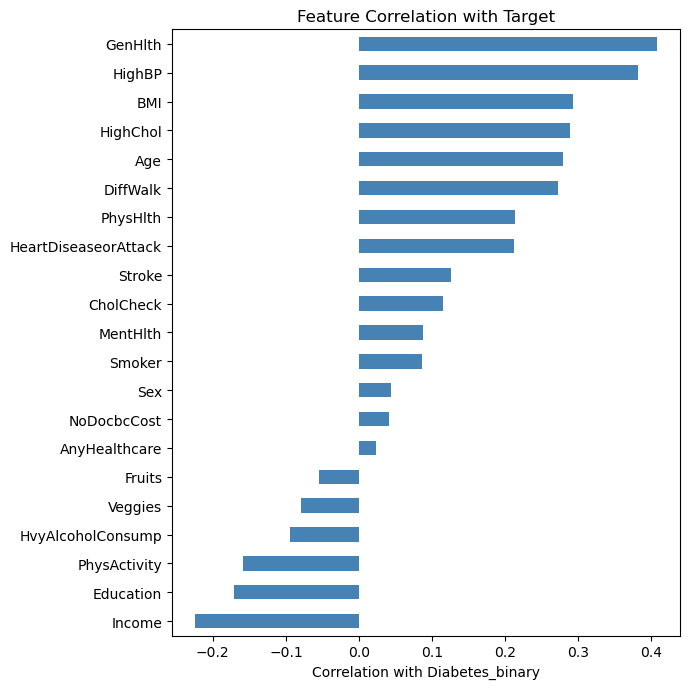

GenHlth                 0.408
HighBP                  0.382
BMI                     0.293
HighChol                0.289
Age                     0.279
DiffWalk                0.273
PhysHlth                0.213
HeartDiseaseorAttack    0.212
Stroke                  0.125
CholCheck               0.115
MentHlth                0.087
Smoker                  0.086
Sex                     0.044
NoDocbcCost             0.041
AnyHealthcare           0.023
Fruits                 -0.054
Veggies                -0.079
HvyAlcoholConsump      -0.095
PhysActivity           -0.159
Education              -0.170
Income                 -0.224
Name: Diabetes_binary, dtype: float64

In [10]:
corr_target = (df.corr()["Diabetes_binary"]
               .drop("Diabetes_binary")
               .sort_values())

plt.figure(figsize=(7, 7))
corr_target.plot(kind="barh", color="steelblue")
plt.xlabel("Correlation with Diabetes_binary")
plt.title("Feature Correlation with Target")
plt.tight_layout()
plt.savefig("EDA_plots/08_target_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr_target.round(3).sort_values(ascending=False)

**What it shows:** The correlation of each feature with `Diabetes_binary`, sorted from strongest positive to strongest negative.

**Observation:** GenHlth has the strongest correlation with diabetes (0.41), followed by HighBP (0.38). BMI, HighChol, Age, and DiffWalk are around 0.27-0.29. Income (-0.22), Education (-0.17), and PhysActivity (-0.16) have negative correlations.

**Why it matters:** Even the strongest value (0.41) is well below 1, so no single feature is enough to predict diabetes. Our models will need to combine several features. Correlation does not mean cause.

### 4.9 Summary Statistics

In [11]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,70692.0,0.50,0.50,0.0,0.0,0.5,1.0,1.0
HighBP,70692.0,0.56,0.50,0.0,0.0,1.0,1.0,1.0
HighChol,70692.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
CholCheck,70692.0,0.98,0.16,0.0,1.0,1.0,1.0,1.0
BMI,70692.0,29.86,7.11,12.0,25.0,29.0,33.0,98.0
Smoker,70692.0,0.48,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,70692.0,0.06,0.24,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,70692.0,0.15,0.35,0.0,0.0,0.0,0.0,1.0
PhysActivity,70692.0,0.70,0.46,0.0,0.0,1.0,1.0,1.0
Fruits,70692.0,0.61,0.49,0.0,0.0,1.0,1.0,1.0


**Observation:** Most of the variables are binary (0/1), so their mean shows the percentage of people with a value of 1. For example, 56% of respondents have high blood pressure. CholCheck (98%) and AnyHealthcare (95%) are almost the same for everyone. MentHlth and PhysHlth are mostly 0 (the median is 0), but some people have up to 30 unhealthy days. BMI reaches 98, which matches the outliers we saw earlier.

**Why it matters:** Features that are almost the same for everyone, like CholCheck and AnyHealthcare, are unlikely to help the models tell the classes apart. The features also have very different scales, so we will need to consider scaling in Preprocessing.

## 5. Preprocessing Pipeline



### 5.1 Duplicate Rows

In [12]:
# step 5.1: we removed the duplicate rows from the dataset to ensure that each observation is unique and to prevent any bias in the analysis. This step is crucial for maintaining the integrity of the data and ensuring accurate results in subsequent analyses.
print("Shape before removing duplicates:", df.shape)   # (70692, 22)

n_dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates removed:", n_dupes)
print("the shape of the DataFrame after removing duplicates:", df.shape)

Shape before removing duplicates: (70692, 22)
Duplicates removed: 1635
the shape of the DataFrame after removing duplicates: (69057, 22)


**What it shows:** 1,635 exact duplicate rows (about 2.3% of the data) were found and removed, leaving 69,057 rows.

**Decision:** Duplicates are dropped before the train/test split.

**Why it matters:** If an identical row lands in both the training and test sets, the model is tested on data it has already seen, which inflates its performance. Removing duplicates first prevents this data leakage and keeps the comparison between models fair. Without this step, 443 test rows would have had an exact copy in the training set.

**Limitation:** In a survey, identical answers can come from different respondents, so some removed rows may not be true duplicates. We chose deduplication as the conservative option for a fair evaluation.

### 5.2 Missing Values



In [13]:
# Step 5.2: Check for missing values
print("Total missing values:", df.isnull().sum().sum())
print("Missing values per column:")
print(df.isnull().sum())

Total missing values: 0
Missing values per column:
Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


**What it shows:** The dataset contains 0 missing values in any column.

**Decision:** No imputation or row removal is needed.

**Why it matters:** Missing values would need to be filled or removed before modeling, since most models cannot handle empty cells. Since there are none here, this step requires no changes to the data.

### 5.3 BMI Outliers


In [14]:
# Step 5.3: Inspect BMI outliers using two common rules
q1, q3 = df['BMI'].quantile([0.25, 0.75])
iqr = q3 - q1
upper_iqr = q3 + 1.5 * iqr
p99 = df['BMI'].quantile(0.99)

print("Max BMI:", df['BMI'].max())
print("IQR upper bound:", upper_iqr  , "| rows above:", (df['BMI'] > upper_iqr).sum())
print("99th percentile:", p99 , "| rows above:", (df['BMI'] > p99).sum())

Max BMI: 98.0
IQR upper bound: 45.0 | rows above: 2180
99th percentile: 52.0 | rows above: 690


In [15]:
# Step 5.3: Cap BMI at the 99th percentile (winsorizing) instead of deleting rows
bmi_cap = df['BMI'].quantile(0.99)
n_capped = (df['BMI'] > bmi_cap).sum()
df['BMI'] = df['BMI'].clip(upper=bmi_cap)   # any value above the cap becomes the cap

print("BMI cap value:", bmi_cap)
print("Rows capped:", n_capped)
print("Max BMI after capping:", df['BMI'].max())

BMI cap value: 52.0
Rows capped: 690
Max BMI after capping: 52.0


**What it shows:** BMI reaches values up to 98. The IQR rule (upper bound 45.0) would flag 2,180 rows (about 3.2%), many of which are clinically plausible cases of severe obesity. The 99th percentile (52.0) affects only 690 rows (1%).

**Decision:** BMI is capped (winsorized) at the 99th percentile instead of removing rows.

**Why it matters:** Capping limits the influence of extreme values, which may come from self-reporting errors in a phone survey, while keeping every row. This matters because these rows are informative: about 75% of respondents with BMI above 52 have prediabetes/diabetes, compared with about 51% overall. Capping also preserves sample size and class balance.

**Limitation:** Genuinely high BMI values above 52 are compressed to 52, which is an accepted trade-off. The cap was computed on the full dataset before the split; since it uses BMI only (not the target) and the cap is 52.0 on the training set alone as well, the effect on the test set is negligible.

### 5.4 Encoding and Column Types

In [16]:
# Step 5.4: Check data types (is encoding needed?) and group columns by type
print(df.dtypes.value_counts())

binary_cols = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke','HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies','HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']

ordinal_continuous_cols = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth','Age', 'Education', 'Income']

# Verify that every binary column really contains only 0 and 1
print("All binary columns are 0/1:", all(df[c].isin([0, 1]).all() for c in binary_cols))
print("Binary:", len(binary_cols), "| Ordinal/continuous:", len(ordinal_continuous_cols))

float64    22
Name: count, dtype: int64
All binary columns are 0/1: True
Binary: 14 | Ordinal/continuous: 7


**What it shows:** All 22 columns are numeric (`float64`), so no categorical encoding is required. The 21 predictors fall into two groups: 14 binary columns (verified to contain only 0/1) and 7 ordinal/continuous columns (BMI, GenHlth, MentHlth, PhysHlth, Age, Education, Income).

**Decision:** No encoding is applied. The two groups are kept separate for the next steps.

**Why it matters:** Models need numeric input, which is already satisfied here. Separating the column types matters because scaling is meaningful only for the ordinal/continuous columns; scaling a 0/1 column would not add value.

### 5.5 Low-Variance Features


In [17]:
# Step 5.5: Share of the most frequent value in each predictor (high share = near-constant)
predictors = df.drop(columns=['Diabetes_binary'])
majority_share = predictors.apply(lambda col: col.value_counts(normalize=True).iloc[0])
print(majority_share.sort_values(ascending=False).round(4).head(6))

CholCheck               0.9748
HvyAlcoholConsump       0.9565
AnyHealthcare           0.9539
Stroke                  0.9364
NoDocbcCost             0.9039
HeartDiseaseorAttack    0.8491
dtype: float64


In [18]:
# Flagged near-constant columns (kept in the data; to be reviewed after modeling)
low_variance_cols = ['CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare']

**What it shows:** The share of the most frequent value was computed for all 21 predictors. Three columns exceed 95%: CholCheck (97.5%), HvyAlcoholConsump (95.7%) and AnyHealthcare (95.4%). Stroke (93.6%) and NoDocbcCost (90.4%) are also highly skewed. The remaining predictors are more evenly distributed.

**Decision:** The three columns above 95% are flagged but kept in the dataset for now.

**Why it matters:** A near-constant feature separates the two classes poorly. However, rarity does not mean uselessness: for example, a rare event such as a stroke can still be strongly related to diabetes. Dropping features before any model has been trained risks losing useful information, so the final decision is left to the team after reviewing feature importance from the Random Forest and XGBoost models.

### 5.6.1 Train/Test Split

In [19]:
# Step 5.6: Stratified 80/20 train/test split with a fixed random_state
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Diabetes_binary'])   # features
y = df['Diabetes_binary']                  # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train class balance:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Test class balance:", y_test.value_counts(normalize=True).round(4).to_dict())

Train shape: (55245, 21) | Test shape: (13812, 21)
Train class balance: {1.0: 0.5082, 0.0: 0.4918}
Test class balance: {1.0: 0.5083, 0.0: 0.4917}


**What it shows:** The data is split into 55,245 training rows and 13,812 test rows (80/20). The class balance is preserved in both sets (about 50.8% / 49.2%).

**Decision:** A stratified split with `random_state=42` is used, after removing duplicates.

**Why it matters:** Stratification keeps both classes proportionally represented in train and test. The fixed `random_state` guarantees that every team member trains and evaluates on exactly the same rows, which makes the comparison between Logistic Regression, Random Forest and XGBoost fair.

### 5.6.2 Leakage check

In [20]:
# Leakage check after the split (uses only variables defined in 5.6.1)
train_check = X_train.copy(); train_check['Diabetes_binary'] = y_train
test_check = X_test.copy();   test_check['Diabetes_binary'] = y_test

overlap_full = train_check.merge(test_check, how='inner')
print("Fully identical rows shared between train and test:", len(overlap_full))

feature_cols = [c for c in df.columns if c != 'Diabetes_binary']
print("Rows with identical features (any target):", df.duplicated(subset=feature_cols, keep=False).sum())

Fully identical rows shared between train and test: 0
Rows with identical features (any target): 818


**Leakage check:** After the split, 0 fully identical rows are shared between the training and test sets, confirming that removing duplicates worked as intended.

**Conflicting rows:** 818 rows (about 1.2%) have identical features but different target values, i.e. 409 pairs of respondents with the same answers but different diabetes status. They were kept: in survey data this is legitimate, there is no way to know which label is "correct", and their effect is small (it limits the best possible accuracy by only about 0.6%).

### 5.7 Scaling


In [21]:
# Step 5.7: Standardize ordinal/continuous columns (fit on TRAIN only to avoid leakage)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[ordinal_continuous_cols] = scaler.fit_transform(X_train[ordinal_continuous_cols])
X_test_scaled[ordinal_continuous_cols] = scaler.transform(X_test[ordinal_continuous_cols])

print(X_train_scaled[ordinal_continuous_cols].mean().round(3))
print(X_train_scaled[ordinal_continuous_cols].std().round(3))

BMI          0.0
GenHlth     -0.0
MentHlth     0.0
PhysHlth    -0.0
Age          0.0
Education   -0.0
Income       0.0
dtype: float64
BMI          1.0
GenHlth      1.0
MentHlth     1.0
PhysHlth     1.0
Age          1.0
Education    1.0
Income       1.0
dtype: float64


**What it shows:** The 7 ordinal/continuous columns are standardized (mean 0, standard deviation 1) using a StandardScaler fitted on the training set only. The 14 binary columns are left unchanged.

**Decision:** Two versions of the split are kept: unscaled (for Random Forest and XGBoost) and scaled (for Logistic Regression).

**Why it matters:** Fitting the scaler on the full dataset would leak information from the test set into training. Tree-based models are not sensitive to feature scale, while Logistic Regression is.

**Limitation:** MentHlth and PhysHlth remain right-skewed after scaling, since standardization changes the scale but not the shape of the distribution.

### 5.8 Cross-Validation Setup


In [22]:
# Step 5.8: Shared 5-fold stratified cross-validation setup (on the training set only)
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5)

for i, (tr_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Fold {i}: train={len(tr_idx)}, validation={len(val_idx)}, "
          f"validation positive rate={y_train.iloc[val_idx].mean():.4f}")

Fold 1: train=44196, validation=11049, validation positive rate=0.5083
Fold 2: train=44196, validation=11049, validation positive rate=0.5083
Fold 3: train=44196, validation=11049, validation positive rate=0.5082
Fold 4: train=44196, validation=11049, validation positive rate=0.5082
Fold 5: train=44196, validation=11049, validation positive rate=0.5082


**What it shows:** The training set is divided into 5 stratified folds. Each fold uses 44,196 rows for training and 11,049 rows for validation, with the class balance preserved (about 50.8% positive).

**Decision:** All members use `StratifiedKFold(n_splits=5)` (equivalent to `cv=5` in scikit-learn), without shuffling, on `train_data.csv` (or `train_data_scaled.csv`) and without reordering its rows. The test set is not used during cross-validation.

**Why it matters:** The same folds for every model make the cross-validation scores directly comparable. Keeping the test set untouched until the final evaluation prevents overly optimistic results.

**Limitation (Logistic Regression):** the scaler was fitted on the full training set before cross-validation, so each validation fold slightly influenced the scaling statistics. This minor leakage affects only the cross-validation scores of Logistic Regression, not the test set. Wrapping the scaler and the model in a scikit-learn Pipeline would remove it.

### 5.9 Feature Selection


In [23]:
# Step 5.9: Rank features by absolute correlation with the target (training set only)
corr_with_target = X_train.corrwith(y_train).abs().sort_values(ascending=False)
print(corr_with_target.round(3))

GenHlth                 0.397
HighBP                  0.372
BMI                     0.303
HighChol                0.283
Age                     0.275
DiffWalk                0.267
Income                  0.213
HeartDiseaseorAttack    0.207
PhysHlth                0.207
Education               0.162
PhysActivity            0.151
Stroke                  0.121
CholCheck               0.120
HvyAlcoholConsump       0.098
MentHlth                0.082
Smoker                  0.076
Veggies                 0.076
Fruits                  0.044
Sex                     0.042
NoDocbcCost             0.038
AnyHealthcare           0.027
dtype: float64


**What it shows:** Features were ranked by their absolute correlation with the target, computed on the training set only. GenHlth (0.397) and HighBP (0.372) are the strongest. The weakest are AnyHealthcare (0.027), NoDocbcCost (0.038), Sex (0.042) and Fruits (0.044). Notably, CholCheck is near-constant (97.5%) yet still shows a correlation of 0.12, higher than Smoker, Fruits and Sex.

**Decision:** All 21 features are kept for modeling. The ranking is a reference, not a filter. With only 21 features, dimensionality is not a concern, tree-based models down-weight weak features on their own, and logistic regression is regularized (C=0.1). Removing features without evidence that it improves performance would risk losing useful information.

**Why it matters:** Correlation only captures linear relationships, so a weakly correlated feature may still be useful to tree-based models. The CholCheck example also shows that a near-constant feature is not necessarily uninformative. The final feature selection, if necessary, can rely on the models' feature importance results (Random Forest and XGBoost); in this phase all 21 features were kept.

## 6. Preprocessed Dataset Ready for Modeling


In [24]:
# Section 6: Save the cleaned dataset and the shared train/test splits
df.to_csv('Dataset/preprocessed_data.csv', index=False)

# Unscaled split (for Random Forest and XGBoost)
train_df = X_train.copy();  train_df['Diabetes_binary'] = y_train
test_df = X_test.copy();    test_df['Diabetes_binary'] = y_test
train_df.to_csv('Dataset/train_data.csv', index=False)
test_df.to_csv('Dataset/test_data.csv', index=False)

# Scaled split (for Logistic Regression)
train_scaled_df = X_train_scaled.copy();  train_scaled_df['Diabetes_binary'] = y_train
test_scaled_df = X_test_scaled.copy();    test_scaled_df['Diabetes_binary'] = y_test
train_scaled_df.to_csv('Dataset/train_data_scaled.csv', index=False)
test_scaled_df.to_csv('Dataset/test_data_scaled.csv', index=False)

print("Saved 5 files to Dataset/")

Saved 5 files to Dataset/


**Files produced in `Dataset/`:**
- `preprocessed_data.csv`: the full cleaned dataset (69,057 rows, duplicates removed, BMI capped), unscaled.
- `train_data.csv` / `test_data.csv`: the shared 80/20 stratified split (unscaled), for Random Forest and XGBoost.
- `train_data_scaled.csv` / `test_data_scaled.csv`: the same split with the 7 ordinal/continuous columns standardized, for Logistic Regression.

**For Members 4, 5 and 6:** load the matching pair of files instead of splitting the raw data again. This guarantees all three models are trained and tested on identical rows. For cross-validation, use only the training file and keep the test set untouched until the final evaluation.

## 7. Key Insights & Challenges

### 7.1 EDA Insights

1. The classes are perfectly balanced, with 35,346 records in each class.
2. There are 1,635 duplicate rows. Preprocessing needs to decide whether to keep or remove them.
3. Most respondents have a BMI around 26-27 (the peak of the histogram, about 15,000 records).
4. BMI values close to 98 are most likely recording errors. Preprocessing needs to decide whether to cap or remove them.
5. HighBP and BMI have a positive relationship with diabetes, meaning diabetes is more common when they are high. PhysActivity and Education have a negative relationship, meaning diabetes is less common when they are higher.
6. The diabetes rate increases with age until the 70-74 age group, then decreases slightly in the oldest groups.
7. GenHlth is the strongest feature (0.41), but it is not enough on its own because the value is far from 1. Our models will need to combine several features.

### 7.2 Preprocessing Insights & Challenges

1. Removing the 1,635 duplicate rows before the train/test split prevents identical rows from appearing in both sets, which would inflate the evaluation results.
2. BMI values up to 98 were capped at the 99th percentile (52.0) instead of being deleted. The IQR rule would have flagged 2,180 rows (about 3.2%), including clinically plausible values, while the percentile cap affects only 690 rows (1%).
3. Checking all 21 predictors showed that CholCheck, HvyAlcoholConsump and AnyHealthcare are near-constant (above 95%), not only the two noted during EDA. They were flagged but kept, because a rare feature can still be informative and the decision depends on model feature importance.
4. No encoding was needed because all columns are numeric, but columns were grouped into binary and ordinal/continuous so that scaling is applied only where it makes sense.
5. The scaler was fitted on the training set only to avoid data leakage. Scaled and unscaled versions of the same split are provided so each model uses the appropriate one.
6. The fixed split (`random_state=42`) is what makes the comparison between Logistic Regression, Random Forest and XGBoost fair.
7. 409 pairs of rows share identical features but have opposite labels. They are kept as legitimate survey responses and represent a small irreducible error floor (about 0.6%).
8. A shared 5-fold stratified cross-validation split is defined on the training set (without shuffling), so all models are validated on the same folds.